Customer-Genre Matrix:
[[5 3 0 2 4]
 [4 2 1 3 5]
 [1 5 4 0 2]
 [2 4 5 1 3]
 [5 1 0 4 2]
 [3 2 4 5 1]]

Genre-Book Matrix:
[[0.9 0.2 0.5 0.1]
 [0.3 0.8 0.2 0.4]
 [0.1 0.5 0.9 0.3]
 [0.4 0.2 0.3 0.8]
 [0.7 0.4 0.1 0.5]]

Dot Product of Customer 1 and Customer 2:
52

Customer-Book Score Matrix (6 x 4):
[[9.  5.4 4.1 5.3]
 [9.  5.5 4.7 6.4]
 [4.2 7.  5.3 4.3]
 [6.  7.5 6.9 5.6]
 [7.8 3.4 4.1 5.1]
 [6.4 5.6 7.1 6.8]]

Transpose of Customer-Genre Matrix:
[[5 4 1 2 5 3]
 [3 2 5 4 1 2]
 [0 1 4 5 0 4]
 [2 3 0 1 4 5]
 [4 5 2 3 2 1]]

Inverse of Square Matrix:
[[ 0.6 -0.2]
 [-0.2  0.4]]

Identity Matrix after multiplication:
[[ 1.00000000e+00  0.00000000e+00]
 [-5.55111512e-17  1.00000000e+00]]

Element-wise Addition:
[[10  6  0  4  8]
 [ 8  4  2  6 10]
 [ 2 10  8  0  4]
 [ 4  8 10  2  6]
 [10  2  0  8  4]
 [ 6  4  8 10  2]]

Element-wise Multiplication:
[[25  9  0  4 16]
 [16  4  1  9 25]
 [ 1 25 16  0  4]
 [ 4 16 25  1  9]
 [25  1  0 16  4]
 [ 9  4 16 25  1]]

Scalar Multiplication:
[[10  6  0 

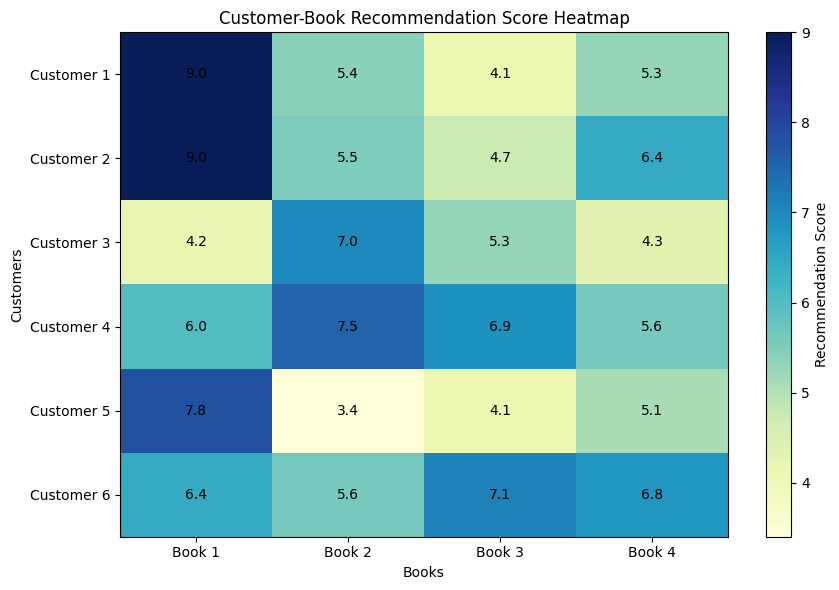

In [1]:

# Experiment 1: Vector and Matrix Operations for Deep Learning

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------
# TASK 1: Create Customer-Genre and Genre-Book Matrices
# ------------------------------------------------

# Customer-Genre Matrix (6 x 5)
# Rows represent customers
# Columns represent genres

customer_genre = np.array([
    [5, 3, 0, 2, 4],
    [4, 2, 1, 3, 5],
    [1, 5, 4, 0, 2],
    [2, 4, 5, 1, 3],
    [5, 1, 0, 4, 2],
    [3, 2, 4, 5, 1]
])

# Genre-Book Matrix (5 x 4)
# Rows represent genres
# Columns represent books

genre_book = np.array([
    [0.9, 0.2, 0.5, 0.1],
    [0.3, 0.8, 0.2, 0.4],
    [0.1, 0.5, 0.9, 0.3],
    [0.4, 0.2, 0.3, 0.8],
    [0.7, 0.4, 0.1, 0.5]
])

print("Customer-Genre Matrix:")
print(customer_genre)

print("\nGenre-Book Matrix:")
print(genre_book)


# ------------------------------------------------
# TASK 2: Vector and Matrix Operations
# ------------------------------------------------

# Dot Product of two customer vectors
dot_product = np.dot(customer_genre[0], customer_genre[1])

print("\nDot Product of Customer 1 and Customer 2:")
print(dot_product)

# Matrix Multiplication
score_matrix = np.matmul(customer_genre, genre_book)

print("\nCustomer-Book Score Matrix (6 x 4):")
print(score_matrix)

# Transpose
transpose_matrix = customer_genre.T

print("\nTranspose of Customer-Genre Matrix:")
print(transpose_matrix)

# Inverse (only for square matrices)
square_matrix = np.array([
    [2, 1],
    [1, 3]
])

inverse_matrix = np.linalg.inv(square_matrix)

print("\nInverse of Square Matrix:")
print(inverse_matrix)

# Verify inverse
print("\nIdentity Matrix after multiplication:")
print(np.matmul(square_matrix, inverse_matrix))

# Element-wise Addition
addition = customer_genre + customer_genre

print("\nElement-wise Addition:")
print(addition)

# Element-wise Multiplication
multiplication = customer_genre * customer_genre

print("\nElement-wise Multiplication:")
print(multiplication)

# Element-wise Scalar Multiplication
scalar_multiplication = customer_genre * 2

print("\nScalar Multiplication:")
print(scalar_multiplication)


# ------------------------------------------------
# TASK 3: Cosine Similarity Between Customers
# ------------------------------------------------

def cosine_similarity(v1, v2):
    return np.dot(v1, v2) / (
        np.linalg.norm(v1) * np.linalg.norm(v2)
    )

# Create 6 x 6 similarity matrix
similarity_matrix = np.zeros((6, 6))

for i in range(6):
    for j in range(6):
        similarity_matrix[i, j] = cosine_similarity(
            customer_genre[i],
            customer_genre[j]
        )

print("\nCustomer Cosine Similarity Matrix:")
print(np.round(similarity_matrix, 3))

# Find the two most similar different customers
similarity_copy = similarity_matrix.copy()
np.fill_diagonal(similarity_copy, -1)

i, j = np.unravel_index(
    np.argmax(similarity_copy),
    similarity_copy.shape
)

print("\nMost Similar Customers:")
print("Customer", i + 1, "and Customer", j + 1)
print("Cosine Similarity:", round(similarity_matrix[i, j], 3))


# ------------------------------------------------
# TASK 4: Dense Layer Calculation (y = Wx + b)
# ------------------------------------------------

# Select Customer 1 as input vector
x = customer_genre[0]

# Weight matrix (4 x 5)
W = genre_book.T

# Bias vector (4,)
b = np.array([0.5, 0.2, 0.3, 0.1])

# Manual Dense Layer Calculation
y = np.dot(W, x) + b

print("\nDense Layer Calculation:")
print("Input Vector (x):")
print(x)

print("\nWeight Matrix (W):")
print(W)

print("\nBias Vector (b):")
print(b)

print("\nOutput y = Wx + b:")
print(y)

# Verify with the first row of score matrix
print("\nVerification:")
print("Score Matrix Row 1 + Bias:")
print(score_matrix[0] + b)


# ------------------------------------------------
# TASK 5: Visualize Score Matrix using Heatmap
# ------------------------------------------------

plt.figure(figsize=(9, 6))

plt.imshow(score_matrix, cmap='YlGnBu', aspect='auto')

plt.colorbar(label='Recommendation Score')

plt.title("Customer-Book Recommendation Score Heatmap")
plt.xlabel("Books")
plt.ylabel("Customers")

plt.xticks(
    ticks=np.arange(4),
    labels=['Book 1', 'Book 2', 'Book 3', 'Book 4']
)

plt.yticks(
    ticks=np.arange(6),
    labels=['Customer 1', 'Customer 2',
            'Customer 3', 'Customer 4',
            'Customer 5', 'Customer 6']
)

# Display values inside heatmap
for i in range(6):
    for j in range(4):
        plt.text(
            j, i,
            round(score_matrix[i, j], 2),
            ha='center',
            va='center',
            color='black'
        )

plt.tight_layout()
plt.show()
